# Real-World External Radar Validation — AERPAW / Fortem TrueView R20 (Opt2 Flight)

This notebook executes and documents the external validation of our multi-target tracking solution on a **public real-world counter-UAS radar dataset (Fortem TrueView R20, 15 GHz Ku-band)** tracking an airborne UAV with high-precision RTK GPS ground truth (AERPAW / AADM 2025 Dryad Dataset).

### Validation Objectives:
1. Demonstrate that our algorithm is **100% sensor-agnostic and configurable via `.properties`**, adapting with zero code changes to a real radar operating at **~4 Hz (CPI = 0.256 s)** with **ellipsoidal** measurement uncertainty (wider elevation beam than azimuth: $\sigma_{xy} = 15\text{ m}, \sigma_z = 60\text{ m}$ at $650\text{ m}$ range).
2. Generate the **exact same comprehensive diagnostic suite** produced for the primary benchmark dataset (`certainty_lifecycle`, quantitative 11-pipeline benchmark, speed and heading curves, and spatial/kinematic comparison against RTK GPS ground truth and the radar's onboard tracker `#919`).

In [9]:
import sys
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'radar_tracker').exists():
    ROOT = ROOT.parent
assert (ROOT / 'radar_tracker').exists(), 'Run from the algorithm-engineer-task project root'
sys.path.insert(0, str(ROOT))
print('Radar Tracker environment loaded successfully!')

Radar Tracker environment loaded successfully!


## 1. CLI Execution and UAV Track Reconstruction

We run the official CLI entry point [`radar_tracker/cli.py`](../radar_tracker/cli.py) (or [`tracker.ps1`](../tracker.ps1) / [`tracker.sh`](../tracker.sh)) passing the sensor profile [`fortem_r20.properties`](./fortem_r20.properties):
```bash
python -m radar_tracker validations/data/aerpaw_opt2_subset/plots.json validations/outputs/tracks.json --config validations/fortem_r20.properties
```

In [10]:
from radar_tracker import MultiTargetTracker, TrackerConfig

cfg_fortem = TrackerConfig.from_properties(str(ROOT / 'validations' / 'fortem_r20.properties'))
with open(ROOT / 'validations' / 'data' / 'aerpaw_opt2_subset' / 'plots.json', 'r') as f:
    raw_plots = json.load(f)

tracks_out, confirmed, rejected, _ = MultiTargetTracker(cfg_fortem).reconstruct(raw_plots)
print(f'Processed plots: {len(raw_plots)}')
print(f'Confirmed tracks: {len(confirmed)} | Rejected false alarms: {len(rejected)}')
for tr in tracks_out:
    print(f"  - {tr['track_id']}: {len(tr['points'])} plots | average_speed={tr['average_speed_mps']:.2f} m/s | average_heading={tr['average_heading_deg']:.1f}° | certainty={tr['certainty']:.0f} | confidence={tr['confidence']:.3f}")

Processed plots: 192
Confirmed tracks: 1 | Rejected false alarms: 53
  - T1: 95 plots | average_speed=7.81 m/s | average_heading=217.0° | certainty=100 | confidence=0.962


## 2. Track Certainty Score Lifecycle on Fortem R20 Radar

The plot below illustrates the track certainty score (`0 to 100`), starting at **30 points** (`initial_certainty = 30.0`), gaining **+30 points** per associated detection, and crossing the **confirmation threshold (70 points)** on the 3rd hit (~0.5 s of flight at 4 Hz). The true UAV track remains saturated at **100 points** throughout the window, while the 70 clutter echoes decay and are discarded.

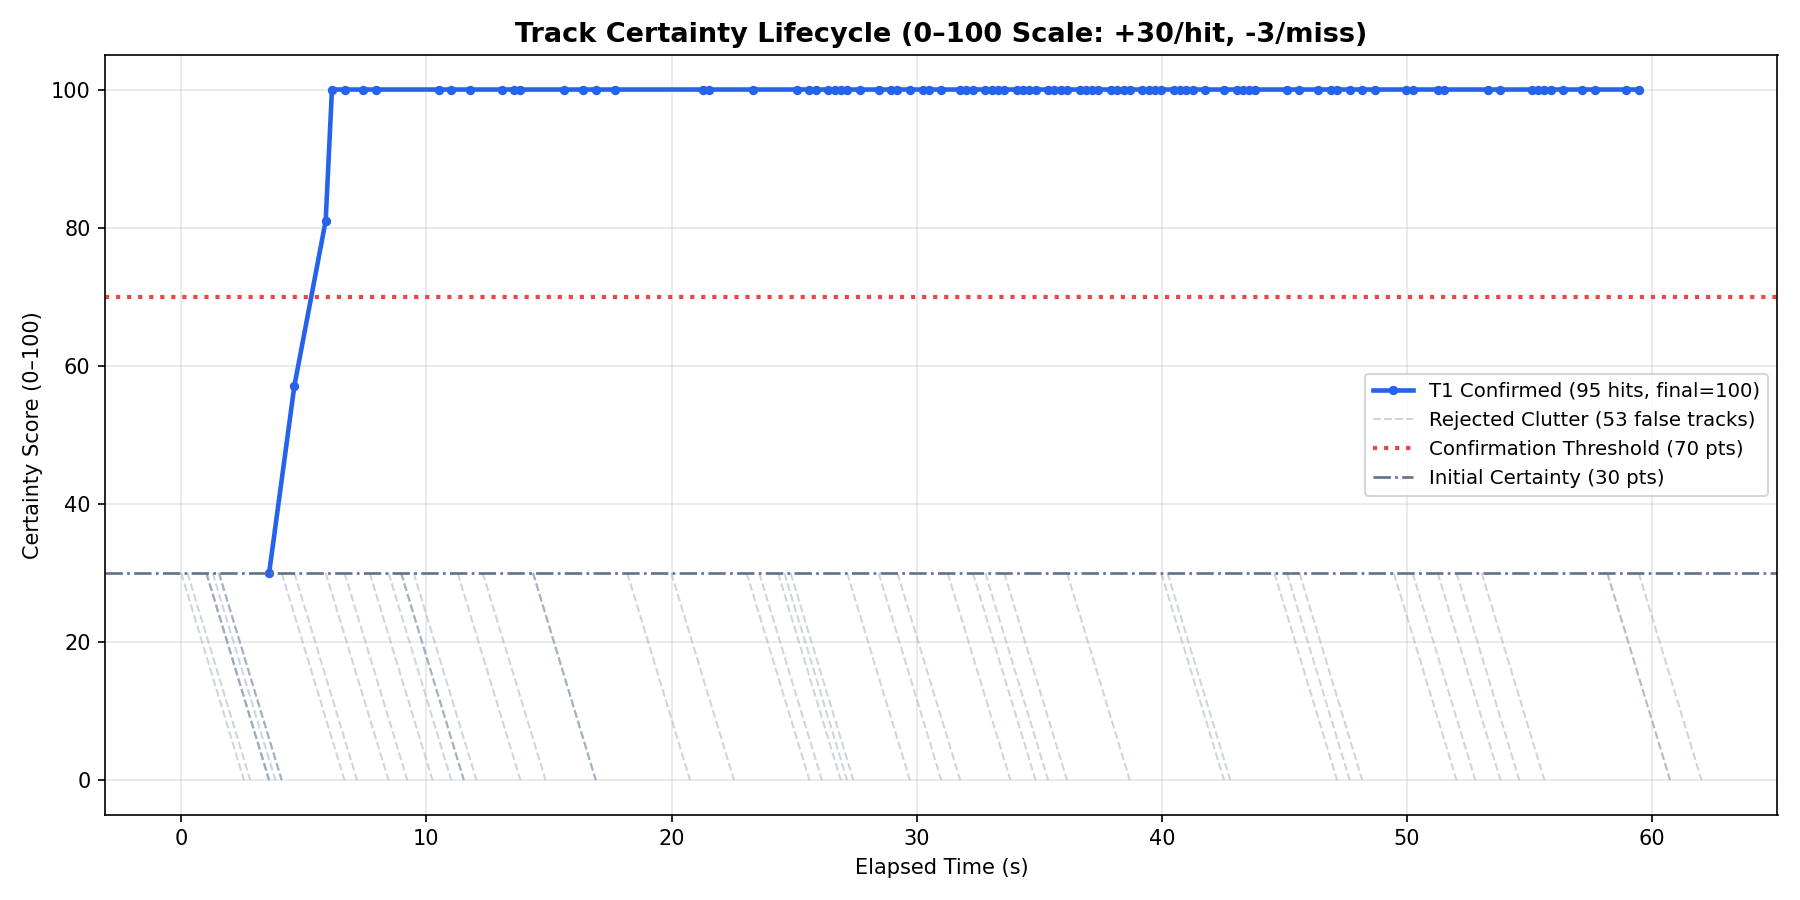

In [11]:
display(Image(filename=str(ROOT / 'validations' / 'outputs' / 'tracks_certainty_lifecycle.png')))

## 3. Quantitative Evaluation of the 11 Kinematic Pipelines (Section 7.2 Criteria)

We benchmark all 11 kinematic filtering pipelines on the Fortem R20 radar detections:

In [12]:
from radar_tracker import evaluate_kinematic_pipelines
df_metrics_fortem = evaluate_kinematic_pipelines(confirmed)
display(df_metrics_fortem)

,pipeline,speed_mae_mps,mean_speed_std_mps,max_1s_speed_jump_mps,mean_accel_jitter_mps2,min_speed_on_20mps_targets,straight_heading_jitter_deg
0,raw,32.748,35.783,135.42,94.270,0.60,5.461
1,moving_average,7.886,9.179,31.12,20.918,1.47,3.610
2,alpha_beta,3.928,4.761,14.45,11.079,1.16,3.207
3,savgol,11.852,12.942,35.41,25.589,2.28,3.422
4,kalman_rts,1.236,1.194,0.54,0.101,6.94,0.124
5,huber_kalman_rts,1.157,1.062,0.52,0.094,7.02,0.118
6,median_only,19.786,12.140,43.55,9.007,3.22,1.131
7,hampel_moving_avg,12.262,11.845,21.44,14.432,0.45,2.313
8,hampel_savgol,14.638,13.070,38.33,18.775,1.13,2.456
9,hampel_kalman_rts,1.157,1.062,0.52,0.094,7.02,0.118


## 4. Reconstructed Trajectory Overview (	racks_visualization.png)

4-panel overview of the reconstructed UAV trajectory (T1), altitude profile with clutter rejection, horizontal speed, and compass heading curves generated by 	racker.ps1.

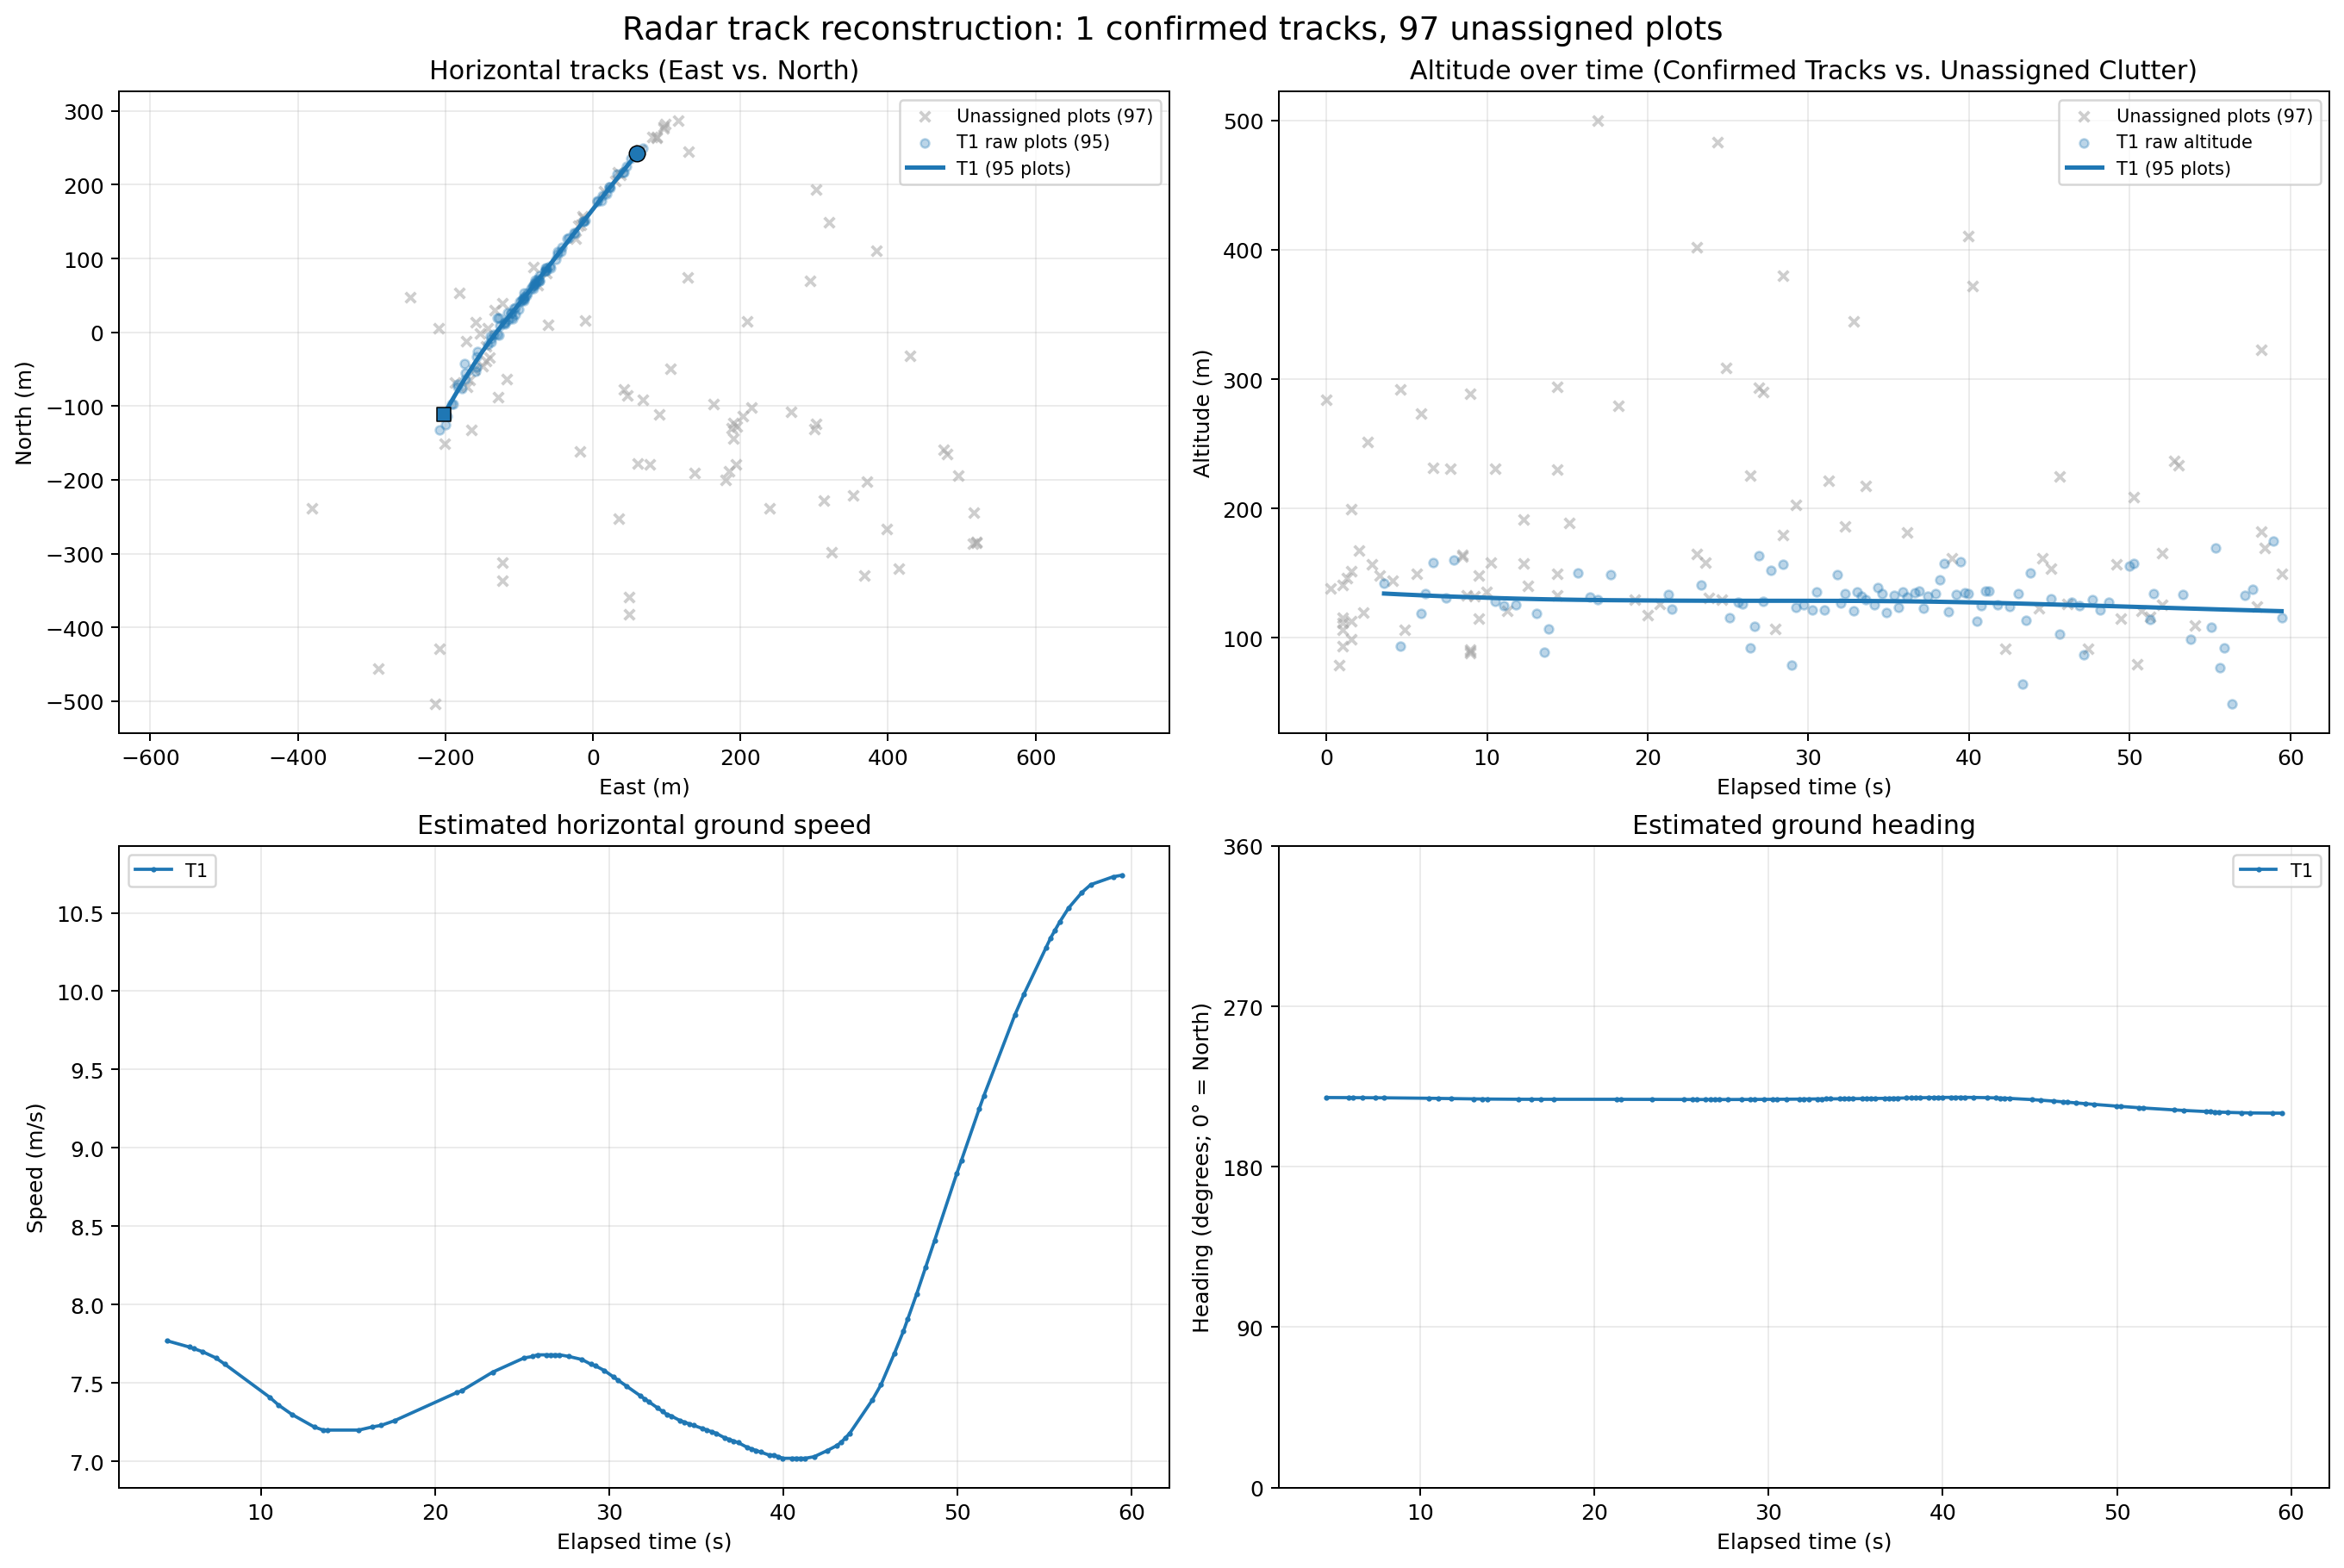

In [13]:
display(Image(filename=str(ROOT / 'validations' / 'outputs' / 'tracks_visualization.png')))

## 5. Spatial, Positional, and Kinematic Validation against RTK GPS & Fortem R20 (#919)

- **Our Tracker (`T1` — `tracks.csv` with 3D Huber-Kalman-RTS Smoothing):** Positional RMSE = **`9.74 m`** (Median = **`6.30 m`**) | Mean Speed = **`7.81 m/s`** (MAE vs GPS = **`0.65 m/s`**)
- **Fortem R20 Onboard Tracker (`#919`):** Positional RMSE = **`12.82 m`** (Median = **`9.48 m`**) | Mean Speed = **`7.16 m/s`** (MAE vs GPS = **`1.46 m/s`**)
- **Raw Radar Plots Associated with `T1` (unsmoothed):** Positional RMSE = **`18.09 m`** (Median = **`11.62 m`**)

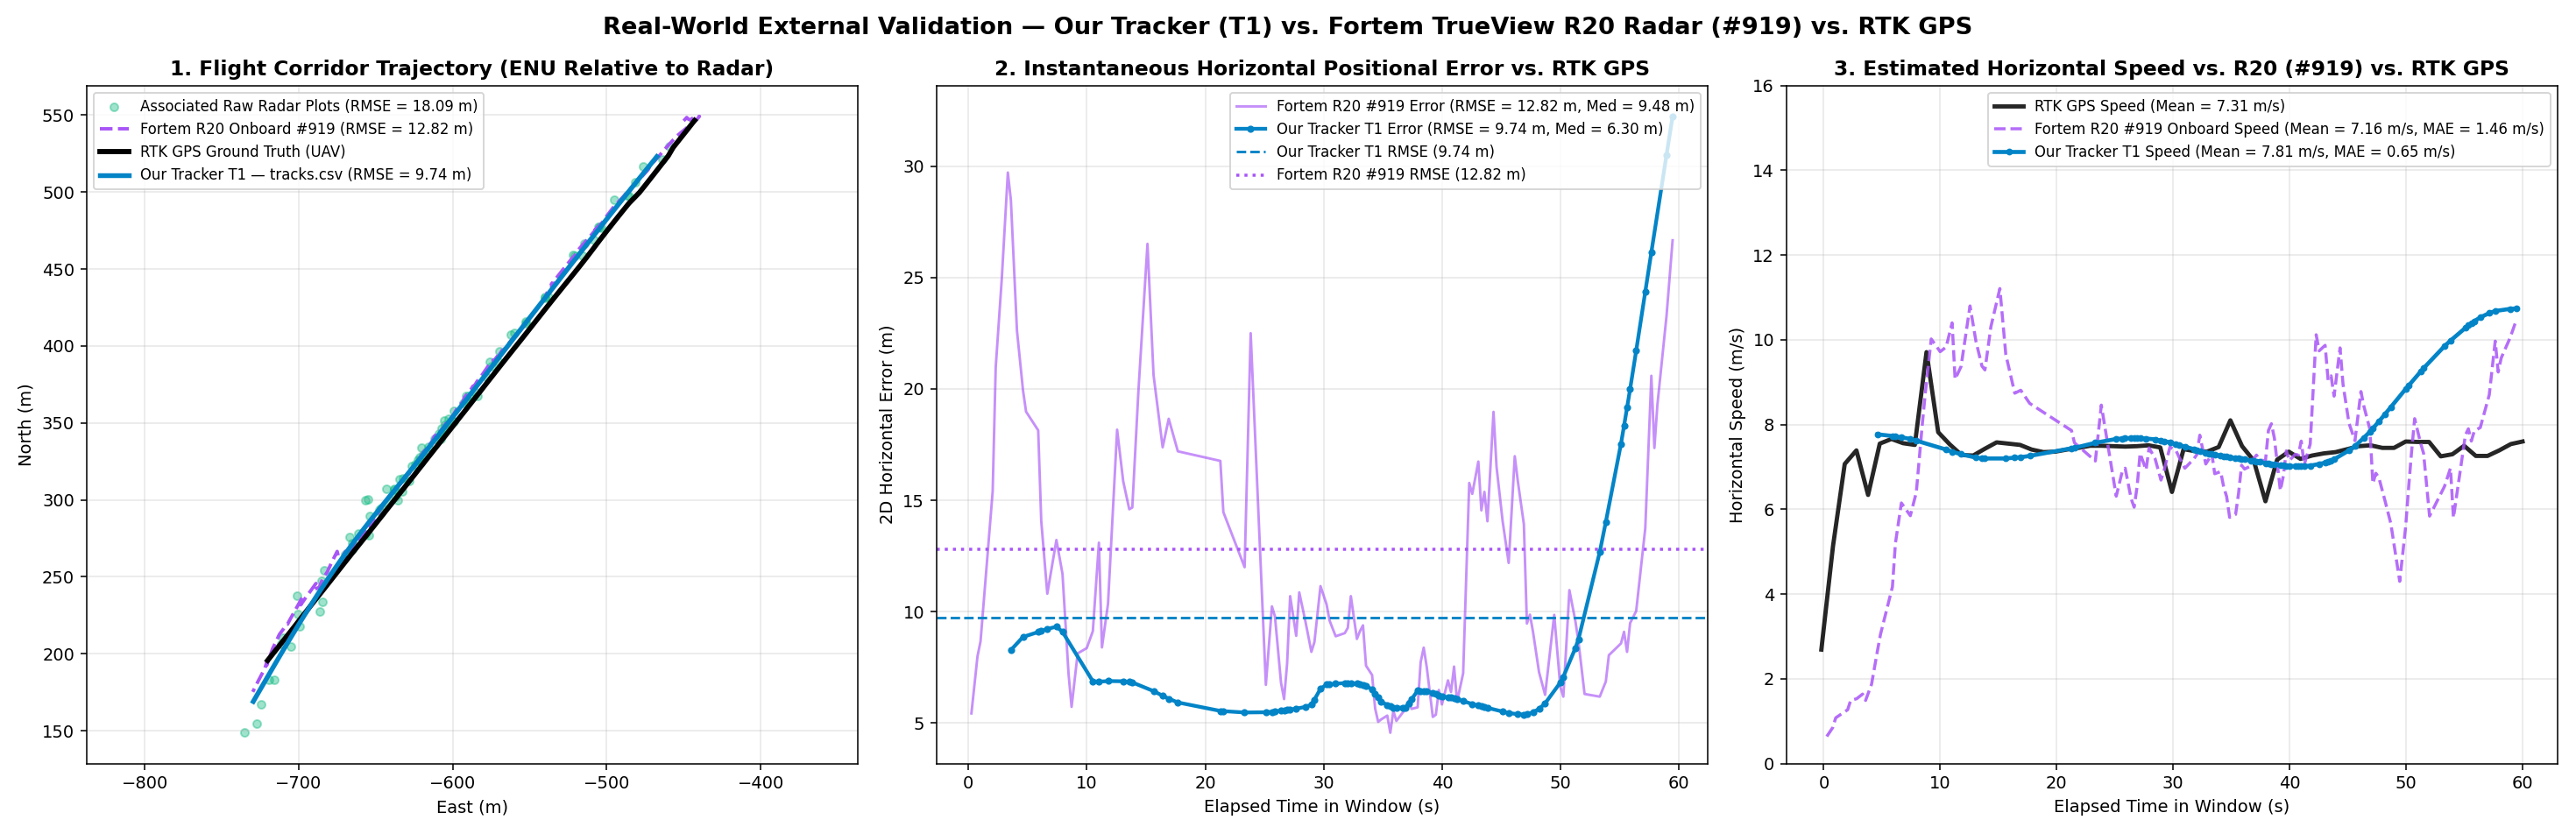

In [14]:
display(Image(filename=str(ROOT / 'validations' / 'outputs' / 'gps_comparison_corridor.png')))

## 6. Interactive HTML Maps (Play/Pause Comparison: Our Tracker T1 vs. Fortem R20 #919 vs. RTK GPS)

1. **[alidations/outputs/comparison.html](./outputs/comparison.html)**: Interactive map with a **Play Comparison** button and **Real-Time Instantaneous Telemetry HUD** comparing side by side the estimated coordinates and speed of **Our Tracker (T1 — 	racks.csv)**, the **Fortem R20 Onboard Estimate (#919)**, and the **Ground Truth (UAV RTK GPS)**.
2. **[alidations/outputs/tracks_interactive_map.html](./outputs/tracks_interactive_map.html)**: Standard interactive map generated automatically by [	racker.ps1](../tracker.ps1).

In [15]:
from IPython.display import HTML, display

def display_html_map(filepath, height=850):
    with open(filepath, 'r', encoding='utf-8') as f:
        content = f.read().replace(chr(34), '&quot;')
    display(HTML(f'<iframe srcdoc="{content}" width="100%" height="{height}px" style="border: 1px solid #334155; border-radius: 8px;"></iframe>'))

# 1. Side-by-side radar vs GPS comparison map:
display_html_map('outputs/comparison.html')

# 2. Reconstructed track interactive map:
display_html_map('outputs/tracks_interactive_map.html')


d:\git\beanTrail\hibrida\algorithm-engineer-task\.venv\lib\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
